##Introduction

I've always found neutrino oscillations fascinating because they tell us something rather unusual about the particles themselves: neutrinos can change flavour as they travel. A neutrino produced as an electron neutrino, for example, can later be detected as a muon or tau neutrino. This happens because flavour states are combinations of different mass eigenstates, and those mass components evolve differently during propagation.

What interests me about this is that the effect connects some fairly abstract ideas from quantum mechanics to something we can actually calculate, simulate, and compare with experimental observations. Instead of treating the oscillation probability as just another equation in particle physics, I want to understand how it behaves when we change the physical parameters and what those changes tell us about neutrino mixing.

In this project, I'll start with the two-flavour approximation, which gives us a relatively simple way to study the basic physics. I'll implement the oscillation probability in Python, investigate how it depends on neutrino energy, propagation distance, mixing angle, and mass-squared difference, and check whether the numerical results agree with analytical predictions. Once that model is working reliably, I'll extend the investigation toward three-flavour oscillations and examine how travelling through matter changes the picture.

My objective isn't to produce a new result in neutrino physics simply by writing a simulation. The equations and phenomena I'm studying are already well established. What I want to build is a transparent, reproducible computational model that helps me understand the physics in greater depth and provides a solid foundation for more realistic neutrino phenomenology.

By the end, I want this notebook to do more than generate a few oscillation plots. I want it to explain where those plots come from, why their behaviour makes physical sense, how reliably the model reproduces the expected results, and where its simplifying assumptions stop being adequate.

## Research Objectives

The main objectives of this project are:

1. **Build a working vacuum oscillation model.** Implement the two-flavour transition and survival probabilities in Python, starting from the analytical expressions.

2. **Investigate parameter dependence.** Study how changes in neutrino energy, propagation distance, mixing angle, and mass-squared difference affect the oscillation pattern.

3. **Verify the numerical results.** Compare calculated oscillation lengths and transition probabilities with analytical predictions, and test basic consistency conditions such as probability conservation.

4. **Extend the model to three flavours.** Introduce the PMNS mixing framework to investigate oscillations among electron, muon, and tau neutrinos.

5. **Explore matter effects.** Examine how neutrino propagation through matter differs from propagation in vacuum and identify the physical reason for that difference.

6. **Document the model's limitations.** Clearly distinguish the approximations used in each stage from the more complete physics needed to describe realistic neutrino experiments.

The broader aim is to develop a computational understanding of neutrino oscillations that I can build on as I continue studying particle physics.


# 2. Theoretical Framework

## 2.1 Flavour States and Mass Eigenstates

To understand neutrino oscillations, I first need to distinguish between two ways of describing a neutrino: its flavour and its mass.

Neutrinos are produced and detected through weak interactions, which identify them as electron neutrinos (\(\nu_e\)), muon neutrinos (\(\nu_\mu\)), or tau neutrinos (\(\nu_\tau\)). These are known as flavour states.

However, flavour states do not correspond directly to states of definite mass. Instead, each flavour state is a quantum-mechanical superposition of mass eigenstates. For a two-flavour system, I can express this relationship using a single mixing angle, \(\theta\):

$$
|\nu_\alpha\rangle =
\cos\theta|\nu_1\rangle+
\sin\theta|\nu_2\rangle
$$

$$
|\nu_\beta\rangle =
-\sin\theta|\nu_1\rangle+
\cos\theta|\nu_2\rangle
$$

Here, \(|\nu_1\rangle\) and \(|\nu_2\rangle\) are the mass eigenstates, while \(|\nu_\alpha\rangle\) and \(|\nu_\beta\rangle\) represent two flavour states. The mixing angle determines how the flavour states are composed of the mass eigenstates.

This distinction is central to the oscillation phenomenon. If flavour states were also states of definite mass, the relative phase evolution responsible for oscillations would not arise in this way.

## 2.2 Why Do Neutrinos Oscillate?

The key idea is that different mass eigenstates evolve with different quantum-mechanical phases as they propagate.

Suppose a neutrino is produced in flavour state \(|\nu_\alpha\rangle\). Using the mixing relations above, its initial state contains contributions from both mass eigenstates. As the neutrino travels, each component accumulates a phase determined by its energy and propagation time.

In natural units, where \(\hbar=c=1\), the evolution of a mass eigenstate can be written as

$$
|\nu_i(L)\rangle =
e^{-iE_iL}|\nu_i\rangle,
$$

where \(E_i\) is the energy of mass eigenstate \(i\), and \(L\) is the propagation distance. This expression assumes ultrarelativistic propagation, for which the travel time is approximately equal to the distance in natural units.

The two mass components therefore evolve as

$$
|\nu_\alpha(L)\rangle =
\cos\theta\,e^{-iE_1L}|\nu_1\rangle
+
\sin\theta\,e^{-iE_2L}|\nu_2\rangle.
$$

When I express this evolved state in the flavour basis, the relative phase between the two components determines the probability of detecting either flavour.

For ultrarelativistic neutrinos with a common energy \(E\), the energy difference can be approximated as

$$
E_2-E_1 \approx \frac{\Delta m^2}{2E},
$$

where

$$
\Delta m^2=m_2^2-m_1^2.
$$

The resulting relative phase is approximately

$$
\Delta\phi \approx \frac{\Delta m^2L}{2E}.
$$

This is the origin of the characteristic dependence on the ratio \(L/E\). The relative phase changes with propagation distance, neutrino energy, and the mass-squared difference. As a result, the probability of detecting a particular flavour can change during propagation.

## 2.3 The Two-Flavour Oscillation Probability

Using the mixing relations and the phase evolution described above, the probability of detecting flavour \(\nu_\beta\) after producing flavour \(\nu_\alpha\) is

$$
P(\nu_\alpha\rightarrow\nu_\beta)
=
\sin^2(2\theta)
\sin^2\left(\frac{\Delta m^2L}{4E}\right),
$$

where natural units are used.

For numerical calculations, it is more convenient to express the distance in kilometres, the energy in gigaelectronvolts (GeV), and the mass-squared difference in electronvolts squared (\(\mathrm{eV}^2\)). With these units, the expression becomes

$$
\boxed{
P(\nu_\alpha\rightarrow\nu_\beta)
=
\sin^2(2\theta)
\sin^2\left(
1.267\frac{\Delta m^2L}{E}
\right)
}
$$

The parameters have the following meanings:

* \(\theta\): the mixing angle, expressed in radians when used in Python.
* \(\Delta m^2\): the mass-squared difference, in \(\mathrm{eV}^2\).
* \(L\): the propagation distance, in kilometres.
* \(E\): the neutrino energy, in GeV.

The numerical coefficient \(1.267\) accounts for the conversion between natural units and these practical units.

For this two-flavour model, the survival probability is

$$
\boxed{
P(\nu_\alpha\rightarrow\nu_\alpha)
=
1-P(\nu_\alpha\rightarrow\nu_\beta)
}
$$

This follows from probability conservation: within a two-flavour system, the probabilities of detecting the original flavour and the other flavour must sum to one.

## 2.4 Understanding the Parameters

Before implementing the equation, I want to understand what each parameter actually controls.

**Mixing angle, \(\theta\)**

The factor \(\sin^2(2\theta)\) determines the maximum possible transition probability:

$$
P_{\max}=\sin^2(2\theta).
$$

A larger value of this factor allows more pronounced flavour conversion. In the idealized two-flavour model, the maximum reaches one when \(\theta=45^\circ\).

**Mass-squared difference, \(\Delta m^2\)**

The mass-squared difference determines how rapidly the relative phase evolves with distance. A larger magnitude produces a shorter oscillation length.

**Neutrino energy, \(E\)**

For fixed mixing parameters, increasing the energy increases the distance required to accumulate a given phase difference. The oscillation pattern therefore stretches over a longer baseline.

**Propagation distance, \(L\)**

As the neutrino travels, its transition probability oscillates rather than increasing continuously. Depending on the accumulated phase, the probability can rise, fall, or reach a maximum or minimum.

These parameters influence different aspects of the probability, and separating their effects will be important when I begin investigating them systematically in Python.

## 2.5 Scope and Assumptions

The equation developed here describes neutrino oscillations in vacuum within a two-flavour approximation. It assumes coherent propagation, ultrarelativistic neutrinos, and a simplified mixing framework.

Real neutrino oscillations involve three flavours and three mass eigenstates. Their description requires the Pontecorvo–Maki–Nakagawa–Sakata (PMNS) mixing matrix. In addition, interactions with matter can modify the effective propagation of electron neutrinos relative to the other flavours.

I will begin with the two-flavour model because it allows me to understand and verify the basic numerical behaviour before introducing these additional effects. The later sections will extend the framework and examine where the simpler approximation becomes insufficient.


## 3. Computational Methodology

Now that I have established the theoretical basis of neutrino oscillations, I want to investigate how the oscillation probability changes under different physical conditions. Instead of calculating individual cases by hand, I will use Python to evaluate the transition probability over a range of distances and energies.

I will begin with the two-flavour vacuum model. Although this is a simplified description of neutrino oscillations, it provides a useful starting point because the effects of the mixing angle, mass-squared difference, energy, and propagation distance can be studied independently.

### 3.1 The Mathematical Model

For two-flavour neutrino oscillations in vacuum, the transition probability is given by

$$
P(\nu_\alpha \rightarrow \nu_\beta)
=
\sin^2(2\theta)
\sin^2\left(\frac{1.267\,\Delta m^2 L}{E}\right)
$$

Here, the numerical factor 1.267 is used when the quantities are expressed in the following units:

* $\Delta m^2$ is the mass-squared difference in $\text{eV}^2$.
* $L$ is the propagation distance in kilometres.
* $E$ is the neutrino energy in GeV.
* $\theta$ is the mixing angle between the two flavour states.

The model gives the probability that a neutrino produced in one flavour state will be detected in the other flavour state after travelling a distance $L$.

For this investigation, I will initially use a mixing angle of $33^\circ$ and a mass-squared difference of $2.4 \times 10^{-3},\text{eV}^2$. These are illustrative starting values for exploring the model, rather than a claim that the two-flavour approximation reproduces the complete behaviour of real neutrino experiments.

### 3.2 Choice of Computational Parameters

Before running the simulation, I need to define a baseline set of parameters. Keeping some parameters fixed while changing others will help me understand their individual effects on the oscillation probability.

| Parameter                             |                    Initial value | Purpose                                                        |
| ------------------------------------- | -------------------------------: | -------------------------------------------------------------- |
| Mixing angle, $\theta$                |                       $33^\circ$ | Determines the amplitude of oscillations                       |
| Mass-squared difference, $\Delta m^2$ | $2.4 \times 10^{-3},\text{eV}^2$ | Influences the oscillation length                              |
| Neutrino energy, $E$                  |                   $2,\text{GeV}$ | Sets the energy scale for the simulation                       |
| Propagation distance, $L$             |                         Variable | Allows the probability to be studied along the neutrino's path |

These values will serve as the reference configuration for the first simulation. Later, I will vary the parameters systematically and compare the resulting probability curves.

### 3.3 Numerical Approach

The simulation will follow a straightforward sequence:

1. Define the physical parameters and their units.
2. Generate an array of propagation distances.
3. Calculate the transition probability at each distance using the two-flavour model.
4. Plot the probability against distance.
5. Identify the oscillation maxima and minima and compare them with theoretical expectations.

I will use NumPy for numerical calculations and Matplotlib to visualise the results. The probability will be calculated over an entire array of distances, allowing the oscillation pattern to be examined continuously rather than at a handful of isolated points.

### 3.4 Validation Strategy

A numerical result is useful only if I can establish that it behaves as the underlying physics predicts. I will therefore check whether the simulation satisfies several basic expectations.

First, the transition probability must remain between zero and one. Second, the transition probability should vanish at zero propagation distance because the neutrino has not yet travelled far enough for a flavour transition to develop in this idealised model. Finally, the positions of the oscillation maxima and minima should agree with those predicted by the mathematical expression.

These checks will provide a basic validation of the implementation before I move on to investigating the effects of individual parameters.

For now, the objective is not to reproduce an entire neutrino experiment. It is to build a transparent, reproducible model whose behaviour I can understand, test, and extend.


## 4. Implementing the Two-Flavour Oscillation Model

I will begin by translating the theoretical expression into a numerical model using Python. The first step is to calculate the transition probability over a range of propagation distances while keeping the mixing angle, mass-squared difference, and neutrino energy fixed.

This will give me a baseline oscillation curve that I can use to investigate how the probability changes as the neutrino travels through vacuum.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


### 4.1 Defining the Parameters

I will use the initial parameters established in the computational methodology. Since Python's trigonometric functions operate in radians, the mixing angle must be converted from degrees before calculating the probability.

I will also define a range of propagation distances extending to 6000 km. This range is sufficient to show several oscillation cycles for the selected parameters.


In [2]:
# Physical parameters
theta_deg = 33
theta = np.deg2rad(theta_deg)

delta_m2 = 2.4e-3  # Mass-squared difference in eV^2
energy = 2.0       # Neutrino energy in GeV

# Propagation distance in kilometres
L = np.linspace(0, 6000, 10000)

print(f"Mixing angle: {theta_deg} degrees")
print(f"Mass-squared difference: {delta_m2} eV^2")
print(f"Neutrino energy: {energy} GeV")
print(f"Distance range: {L.min():.0f} to {L.max():.0f} km")

Mixing angle: 33 degrees
Mass-squared difference: 0.0024 eV^2
Neutrino energy: 2.0 GeV
Distance range: 0 to 6000 km


### 4.2 Calculating the Transition Probability

With the parameters defined, I can now implement the two-flavour vacuum oscillation formula:

$$
P(\nu_\alpha \rightarrow \nu_\beta)
=
\sin^2(2\theta)
\sin^2\left(\frac{1.267\,\Delta m^2 L}{E}\right)
$$

The calculation is vectorised using NumPy, meaning that the probability is evaluated at every distance in the array simultaneously. This avoids the need for a loop and makes it straightforward to generate a smooth oscillation curve.


In [3]:
# Calculate the transition probability
P_transition = (
    np.sin(2 * theta)**2
    * np.sin(1.267 * delta_m2 * L / energy)**2
)

# Basic numerical checks
print(f"Minimum probability: {P_transition.min():.6f}")
print(f"Maximum probability: {P_transition.max():.6f}")
print(f"Probability at zero distance: {P_transition[0]:.6f}")

assert np.all(P_transition >= 0)
assert np.all(P_transition <= 1)
assert np.isclose(P_transition[0], 0)

print("All basic probability checks passed.")

Minimum probability: 0.000000
Maximum probability: 0.834565
Probability at zero distance: 0.000000
All basic probability checks passed.


### 4.3 Visualising the Oscillation Pattern

The numerical probabilities are more informative when plotted against propagation distance. The graph should reveal a repeating pattern of maxima and minima rather than a probability that increases continuously with distance.

I will plot the transition probability over the selected baseline and include labels, a title, and a grid to make the oscillation pattern easier to interpret.


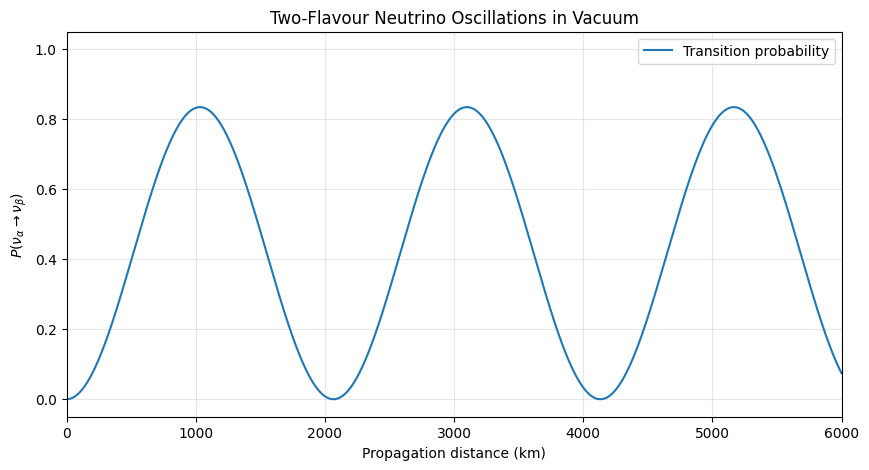

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(L, P_transition, label="Transition probability")

plt.xlabel("Propagation distance (km)")
plt.ylabel(r"$P(\nu_\alpha \rightarrow \nu_\beta)$")
plt.title("Two-Flavour Neutrino Oscillations in Vacuum")

plt.ylim(-0.05, 1.05)
plt.xlim(0, 6000)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

## 5. Initial Observations

The simulation produces an oscillatory transition probability, with repeated maxima and minima as the propagation distance increases. This behaviour reflects the changing relative phase between the neutrino's mass eigenstates.

For the selected parameters, the transition probability begins at zero and rises to a maximum before decreasing again. The probability does not increase indefinitely with distance. Instead, it oscillates because the neutrino's flavour state changes during propagation.

The maximum probability is controlled by the mixing angle. With the chosen value of $33^\circ$, the maximum transition probability is approximately $0.835$, rather than unity. The distance between successive maxima is determined by the mass-squared difference and the neutrino energy.

This initial result provides a baseline for the next stage of the investigation. I will examine the locations of the oscillation maxima and minima and compare them with the predictions of the theoretical model.


## 6. Investigating the Oscillation Length

The initial simulation shows that the neutrino transition probability oscillates as the propagation distance increases. However, visual inspection alone is not enough to establish whether the simulation agrees with the theoretical model.

In this section, I will calculate the oscillation length analytically and compare the predicted positions of the probability maxima and minima with those obtained from the numerical simulation.

The oscillation length describes the distance over which the probability completes one full cycle and returns to the same point in its oscillation pattern. Understanding this quantity will also help me investigate how the neutrino energy and mass-squared difference influence the oscillation behaviour.


### 6.1 Theoretical Prediction

The transition probability in the two-flavour vacuum model is

$$
P(\nu_\alpha \rightarrow \nu_\beta)
=
\sin^2(2\theta)
\sin^2\left(\frac{1.267\,\Delta m^2 L}{E}\right).
$$

For convenience, I will define the oscillation phase as

$$
\phi = \frac{1.267\,\Delta m^2 L}{E}.
$$

Since the function $\sin^2(\phi)$ repeats whenever its phase increases by $\pi$, one complete oscillation corresponds to

$$
\Delta\phi = \pi.
$$

Therefore, the oscillation length is

$$
L_{\mathrm{osc}}
=
\frac{\pi E}{1.267\,|\Delta m^2|}.
$$

Here, $L_{\mathrm{osc}}$ is measured in kilometres when $E$ is in GeV and $\Delta m^2$ is in $\mathrm{eV}^2$.

The absolute value of the mass-squared difference is used because the oscillation length is a positive distance. In this two-flavour vacuum probability, changing the sign of $\Delta m^2$ does not change the predicted transition probability.


In [5]:
# Calculate the theoretical oscillation length
L_osc_theory = np.pi * energy / (1.267 * abs(delta_m2))

# The first maximum occurs at half an oscillation length
L_first_max_theory = L_osc_theory / 2

print(f"Theoretical oscillation length: {L_osc_theory:.2f} km")
print(f"Predicted first maximum: {L_first_max_theory:.2f} km")

Theoretical oscillation length: 2066.29 km
Predicted first maximum: 1033.15 km


### 6.2 Numerical Identification of Maxima and Minima

The theoretical expression predicts where the oscillation maxima and minima should occur. I will now identify these points directly from the numerical probability array.

A local maximum occurs when the transition probability is greater than the values immediately surrounding it. A local minimum occurs when it is lower than the surrounding values.

I will use SciPy's `find_peaks` function to identify these features in the simulated data. For minima, I will apply the same method to the negative probability array, allowing local minima in the original data to be detected as local maxima of its negative.

Because the simulation uses a finite number of distance points, the numerically identified positions may differ slightly from the analytical predictions. This difference is expected to decrease as the distance grid becomes finer.


In [6]:
from scipy.signal import find_peaks

# Identify local maxima
peak_indices, _ = find_peaks(P_transition)

# Identify local minima
minimum_indices, _ = find_peaks(-P_transition)

# Extract the corresponding distances and probabilities
peak_distances = L[peak_indices]
peak_probabilities = P_transition[peak_indices]

minimum_distances = L[minimum_indices]
minimum_probabilities = P_transition[minimum_indices]

print("First five local maxima:")
for distance, probability in zip(peak_distances[:5], peak_probabilities[:5]):
    print(f"Distance = {distance:.2f} km, Probability = {probability:.6f}")

print("\nFirst five local minima:")
for distance, probability in zip(minimum_distances[:5], minimum_probabilities[:5]):
    print(f"Distance = {distance:.2f} km, Probability = {probability:.6f}")

First five local maxima:
Distance = 1033.30 km, Probability = 0.834565
Distance = 3099.31 km, Probability = 0.834565
Distance = 5165.92 km, Probability = 0.834565

First five local minima:
Distance = 2066.01 km, Probability = 0.000000
Distance = 4132.61 km, Probability = 0.000000


### 6.3 Visual Comparison

To make the comparison easier, I will plot the original oscillation curve and mark the numerically identified maxima and minima.

This visualisation will help establish whether the detected points follow the expected oscillation pattern and whether the numerical model behaves consistently with the analytical expression.


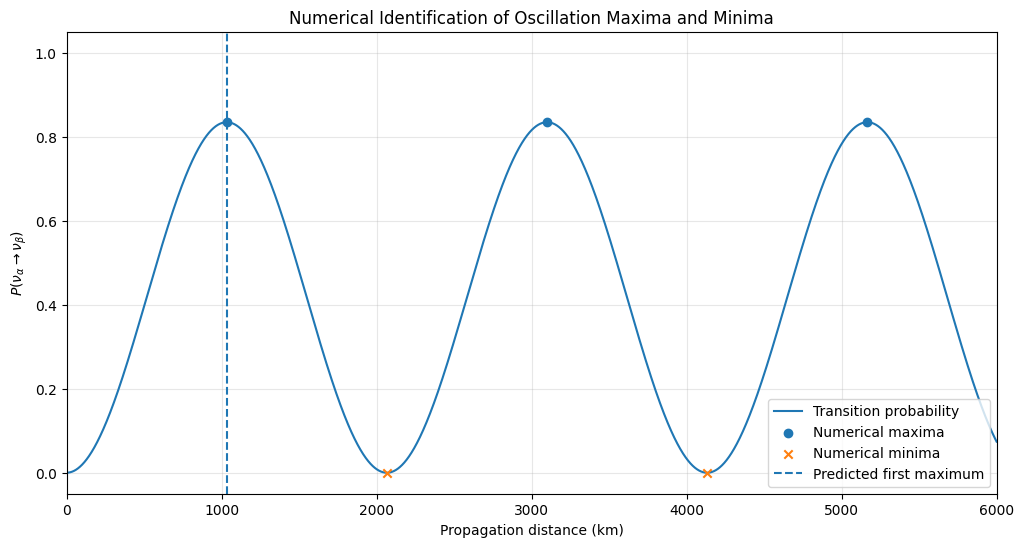

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(L, P_transition, label="Transition probability")
plt.scatter(
    peak_distances,
    peak_probabilities,
    marker="o",
    label="Numerical maxima",
    zorder=3
)
plt.scatter(
    minimum_distances,
    minimum_probabilities,
    marker="x",
    label="Numerical minima",
    zorder=3
)

plt.axvline(
    L_first_max_theory,
    linestyle="--",
    label="Predicted first maximum"
)

plt.xlabel("Propagation distance (km)")
plt.ylabel(r"$P(\nu_\alpha \rightarrow \nu_\beta)$")
plt.title("Numerical Identification of Oscillation Maxima and Minima")
plt.xlim(0, 6000)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

### 6.4 Analytical and Numerical Comparison

The theoretical oscillation length provides a reference against which the numerical results can be checked. For the parameters used here, the oscillation length is approximately $2066\mathrm{km}$.

The first probability maximum is expected at half this distance, approximately $1033\mathrm{km}$. Subsequent maxima occur near $3099\mathrm{km}$ and $5165\mathrm{km}$, while minima occur near $2066\mathrm{km}$ and $4132\mathrm{km}$.

The transition probability at the maxima is approximately $0.835$ for the selected mixing angle of $33^\circ$. At the minima, it approaches zero.

Agreement between the analytical predictions and the numerically identified extrema would support the correctness of the implementation. Any small discrepancy in their positions can be attributed to the finite spacing of the distance grid, rather than a physical difference between the two results.


In [8]:
# Compare the first numerical maximum with the theoretical prediction
L_first_max_numerical = peak_distances[0]

absolute_difference = abs(
    L_first_max_numerical - L_first_max_theory
)

relative_difference = (
    absolute_difference / L_first_max_theory
) * 100

print(f"Theoretical first maximum: {L_first_max_theory:.3f} km")
print(f"Numerical first maximum:   {L_first_max_numerical:.3f} km")
print(f"Absolute difference:       {absolute_difference:.3f} km")
print(f"Relative difference:       {relative_difference:.4f}%")

Theoretical first maximum: 1033.147 km
Numerical first maximum:   1033.303 km
Absolute difference:       0.157 km
Relative difference:       0.0152%


## 7. Investigating Parameter Dependence

The initial simulation showed how the neutrino transition probability varies with propagation distance for a fixed set of parameters. However, the oscillation pattern is not universal. Its behaviour depends on the neutrino energy, the mass-squared difference, and the mixing angle.

In this section, I will investigate these dependencies by varying one parameter at a time while keeping the others fixed. This approach will help me distinguish between changes in the oscillation frequency and changes in the maximum transition probability.

I will begin with neutrino energy, followed by the mass-squared difference and mixing angle. The numerical results will be compared with the analytical predictions wherever possible.


### 7.1 Effect of Neutrino Energy

The oscillation probability depends on neutrino energy through the phase

$$
\phi = \frac{1.267\,\Delta m^2 L}{E}.
$$

For fixed propagation distance and mass-squared difference, increasing the neutrino energy decreases the oscillation phase. Consequently, a higher-energy neutrino generally requires a longer propagation distance to reach the same point in its oscillation cycle.

This relationship is also reflected in the oscillation length:

$$
L_{\mathrm{osc}}
=
\frac{\pi E}{1.267\,|\Delta m^2|}.
$$

The oscillation length is directly proportional to neutrino energy. Therefore, doubling the energy doubles the oscillation length, provided the mass-squared difference remains unchanged.

To examine this behaviour, I will compare the transition probabilities at three different neutrino energies while keeping the mixing angle and mass-squared difference fixed.


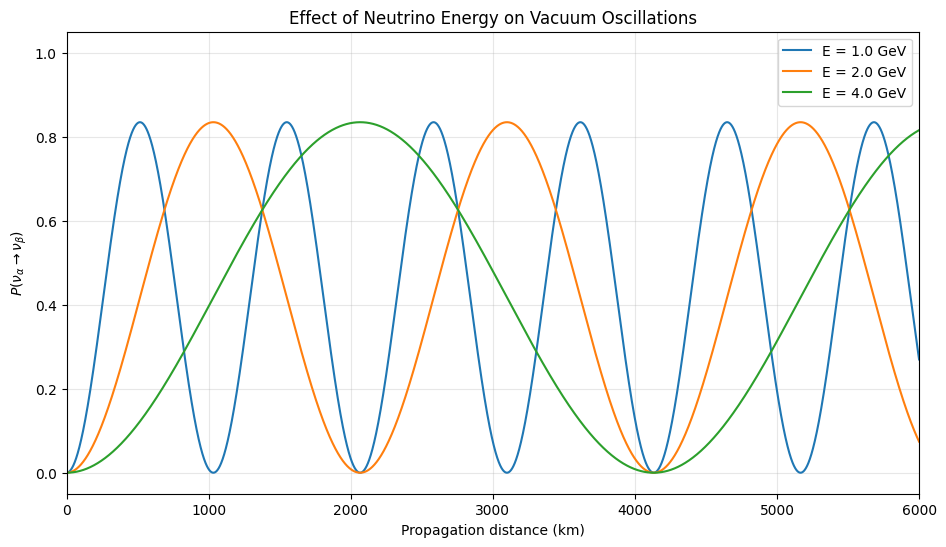

In [9]:
# Neutrino energies in GeV
energies = [1.0, 2.0, 4.0]

plt.figure(figsize=(11, 6))

for E in energies:
    P = (
        np.sin(2 * theta)**2
        * np.sin(1.267 * delta_m2 * L / E)**2
    )

    plt.plot(L, P, label=f"E = {E:.1f} GeV")

plt.xlabel("Propagation distance (km)")
plt.ylabel(r"$P(\nu_\alpha \rightarrow \nu_\beta)$")
plt.title("Effect of Neutrino Energy on Vacuum Oscillations")
plt.xlim(0, 6000)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

### Observations

The graph shows that increasing the neutrino energy stretches the oscillation pattern along the propagation-distance axis. At lower energies, the probability completes more oscillation cycles over the same distance. At higher energies, the cycles are more widely spaced.

The maximum transition probability remains approximately the same across the three curves because the mixing angle has been held constant. In this model, neutrino energy changes the oscillation length but does not change the amplitude of the oscillations.

This distinction is important: the energy controls how quickly the oscillation phase develops with distance, whereas the mixing angle determines the maximum transition probability in the two-flavour vacuum model.


In [10]:
print("Theoretical oscillation lengths")

for E in energies:
    L_osc = np.pi * E / (1.267 * abs(delta_m2))
    print(f"E = {E:.1f} GeV -> L_osc = {L_osc:.2f} km")

Theoretical oscillation lengths
E = 1.0 GeV -> L_osc = 1033.15 km
E = 2.0 GeV -> L_osc = 2066.29 km
E = 4.0 GeV -> L_osc = 4132.59 km


### 7.2 Effect of the Mass-Squared Difference

The mass-squared difference between the neutrino mass eigenstates also determines how rapidly the oscillation phase develops.

The oscillation length is inversely proportional to the magnitude of the mass-squared difference:

$$
L_{\mathrm{osc}}
=
\frac{\pi E}{1.267\,|\Delta m^2|}.
$$

A larger mass-squared difference therefore produces a shorter oscillation length, while a smaller difference produces a longer one.

To investigate this relationship, I will vary the mass-squared difference while keeping the neutrino energy and mixing angle fixed. The values used here are chosen to illustrate the mathematical dependence and should not all be interpreted as independent measurements of the same physical neutrino system.


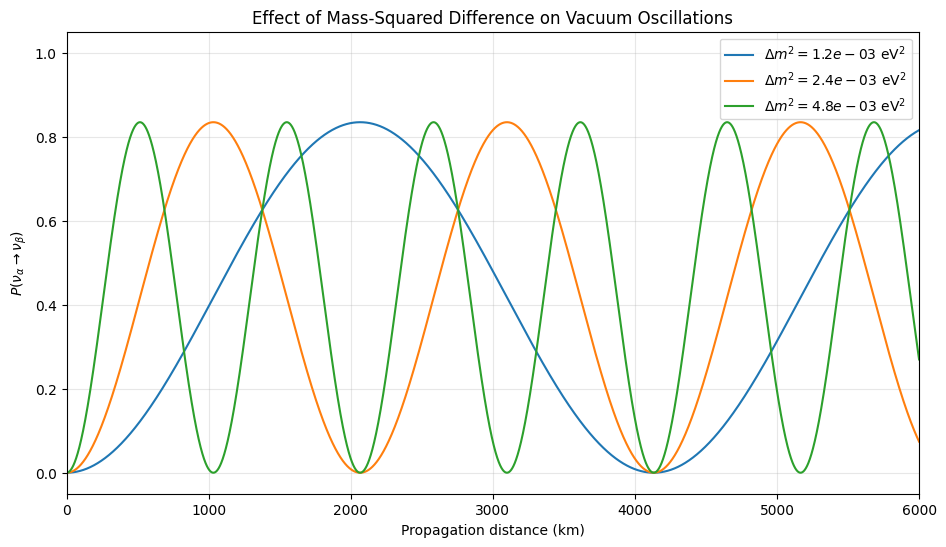

In [11]:
# Mass-squared differences in eV^2
mass_squared_differences = [1.2e-3, 2.4e-3, 4.8e-3]

plt.figure(figsize=(11, 6))

for dm2 in mass_squared_differences:
    P = (
        np.sin(2 * theta)**2
        * np.sin(1.267 * dm2 * L / energy)**2
    )

    plt.plot(L, P, label=rf"$\Delta m^2 = {dm2:.1e}\ \mathrm{{eV}}^2$")

plt.xlabel("Propagation distance (km)")
plt.ylabel(r"$P(\nu_\alpha \rightarrow \nu_\beta)$")
plt.title("Effect of Mass-Squared Difference on Vacuum Oscillations")
plt.xlim(0, 6000)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

### Observations

The graph shows that increasing the magnitude of the mass-squared difference compresses the oscillation pattern, producing more cycles over the same propagation distance. Decreasing it stretches the pattern.

The maximum transition probability remains approximately constant because the mixing angle is unchanged. Thus, within this model, the mass-squared difference controls the oscillation length, while the mixing angle controls the oscillation amplitude.

This result demonstrates that the oscillation pattern depends on both the neutrino's energy and the difference between the squared masses of its mass eigenstates.


In [12]:
print("Theoretical oscillation lengths")

for dm2 in mass_squared_differences:
    L_osc = np.pi * energy / (1.267 * abs(dm2))
    print(f"Delta m^2 = {dm2:.1e} eV^2 -> L_osc = {L_osc:.2f} km")

Theoretical oscillation lengths
Delta m^2 = 1.2e-03 eV^2 -> L_osc = 4132.59 km
Delta m^2 = 2.4e-03 eV^2 -> L_osc = 2066.29 km
Delta m^2 = 4.8e-03 eV^2 -> L_osc = 1033.15 km


### 7.3 Effect of the Mixing Angle

So far, the oscillation curves have changed their spacing while retaining approximately the same maximum probability. I will now investigate the role of the mixing angle.

The transition probability contains the factor

$$
\sin^2(2\theta).
$$

This factor determines the maximum transition probability in the two-flavour vacuum model. When $\theta = 45^\circ$, the factor reaches unity, allowing the transition probability to reach one at its maxima. For smaller mixing angles, the maximum probability is lower.

Unlike the energy and mass-squared difference, the mixing angle changes the amplitude of the oscillations without changing the oscillation length, provided the other parameters remain fixed.


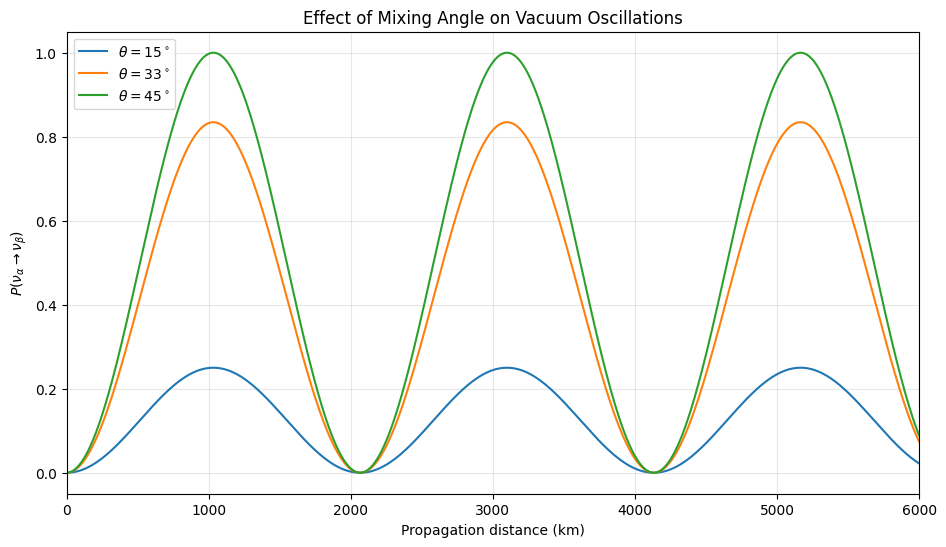

In [13]:
# Mixing angles in degrees
mixing_angles_deg = [15, 33, 45]

plt.figure(figsize=(11, 6))

for angle_deg in mixing_angles_deg:
    angle = np.deg2rad(angle_deg)

    P = (
        np.sin(2 * angle)**2
        * np.sin(1.267 * delta_m2 * L / energy)**2
    )

    plt.plot(L, P, label=rf"$\theta = {angle_deg}^\circ$")

plt.xlabel("Propagation distance (km)")
plt.ylabel(r"$P(\nu_\alpha \rightarrow \nu_\beta)$")
plt.title("Effect of Mixing Angle on Vacuum Oscillations")
plt.xlim(0, 6000)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

### Observations

The curves show that the mixing angle determines the height of the transition-probability maxima. For a mixing angle of $15^\circ$, the maximum probability is relatively low. Increasing the angle to $33^\circ$ raises the maximum probability, while a mixing angle of $45^\circ$ allows complete transitions at the oscillation maxima.

The spacing between successive maxima remains unchanged because the neutrino energy and mass-squared difference have been kept fixed.

This comparison highlights a useful distinction in the two-flavour model: the mixing angle determines the amplitude of the oscillation, whereas the energy and mass-squared difference determine its spatial frequency.


### 7.4 Summary of Parameter Dependence

The parameter investigations reveal three distinct effects within the two-flavour vacuum model.

Increasing the neutrino energy increases the oscillation length, meaning that the probability completes fewer cycles over a fixed propagation distance. Increasing the magnitude of the mass-squared difference decreases the oscillation length, producing more closely spaced cycles. Changing the mixing angle alters the maximum transition probability without changing the oscillation length.

These relationships agree with the analytical expressions used in the simulation. They also show why neutrino oscillation measurements can provide information about neutrino mixing and mass differences.

However, this analysis is still based on a simplified two-flavour model in vacuum. Real neutrino oscillations involve three flavour states, and propagation through matter can modify the oscillation probabilities. I will address these limitations in the next stages of the project.


## 8. Extending the Model to Three Neutrino Flavours

The two-flavour model provided a useful starting point for understanding neutrino oscillations. It allowed me to investigate the effects of neutrino energy, the mass-squared difference, and the mixing angle without introducing too many parameters at once.

However, neutrino oscillations in nature involve three flavour states: electron neutrinos, muon neutrinos, and tau neutrinos. These flavour states are related to three neutrino mass eigenstates through a mathematical object known as the Pontecorvo-Maki-Nakagawa-Sakata (PMNS) mixing matrix.

Extending the simulation to three flavours will allow me to study transitions between different neutrino flavours within a more realistic framework. It will also introduce additional physical parameters, including three mixing angles and a complex phase that can contribute to differences between neutrino and antineutrino oscillations.

I will construct the three-flavour model in vacuum first. Matter effects will be considered separately so that their influence can be investigated without confusing them with the effects of three-flavour mixing itself.


### 8.1 Flavour and Mass Eigenstates

Neutrinos are produced and detected through weak interactions, which identify them by flavour: electron, muon, or tau. However, the states that propagate with definite masses are the mass eigenstates, denoted by $\nu_1$, $\nu_2$, and $\nu_3$.

The flavour states are linear combinations of these mass eigenstates:

$$
|\nu_\alpha\rangle
=
\sum_{i=1}^{3} U_{\alpha i}^{*}|\nu_i\rangle,
$$

where $\alpha = e,\mu,\tau$ and $U$ is the PMNS mixing matrix. The asterisk denotes complex conjugation.

This relationship means that a neutrino produced with a definite flavour generally contains contributions from multiple mass eigenstates. As these components propagate, they accumulate different quantum-mechanical phases because their masses differ. Their relative phases change with distance, modifying the probability that the neutrino will later be detected with a particular flavour.

The PMNS matrix therefore plays a central role in connecting the flavour states measured in experiments to the mass eigenstates that govern propagation.


### 8.2 The PMNS Mixing Matrix

The PMNS matrix describes how the three flavour states are related to the three mass eigenstates. In the standard parameterisation, it is written as

$$
U =
\begin{pmatrix}
c_{12}c_{13} & s_{12}c_{13} & s_{13}e^{-i\delta_{\mathrm{CP}}} \\
-s_{12}c_{23}-c_{12}s_{23}s_{13}e^{i\delta_{\mathrm{CP}}}
& c_{12}c_{23}-s_{12}s_{23}s_{13}e^{i\delta_{\mathrm{CP}}}
& s_{23}c_{13} \\
s_{12}s_{23}-c_{12}c_{23}s_{13}e^{i\delta_{\mathrm{CP}}}
& -c_{12}s_{23}-s_{12}c_{23}s_{13}e^{i\delta_{\mathrm{CP}}}
& c_{23}c_{13}
\end{pmatrix}.
$$

Here,

$$
s_{ij}=\sin\theta_{ij},
\qquad
c_{ij}=\cos\theta_{ij}.
$$

The three mixing angles are $\theta_{12}$, $\theta_{23}$, and $\theta_{13}$. The parameter $\delta_{\mathrm{CP}}$ is the Dirac CP-violating phase.

The mixing angles determine how strongly the flavour states are connected to the mass eigenstates. The complex phase can produce differences between neutrino and antineutrino oscillation probabilities when the relevant interference terms are nonzero.

For this project, I will construct the matrix numerically using NumPy. This will allow the same matrix to be used throughout the subsequent calculations, rather than repeatedly evaluating its individual elements.


In [14]:
import numpy as np

# Mixing angles in degrees
theta12_deg = 33.4
theta23_deg = 49.0
theta13_deg = 8.6

# Convert angles to radians
theta12 = np.deg2rad(theta12_deg)
theta23 = np.deg2rad(theta23_deg)
theta13 = np.deg2rad(theta13_deg)

# Dirac CP phase
delta_cp_deg = 195.0
delta_cp = np.deg2rad(delta_cp_deg)

print("Mixing parameters defined.")
print(f"theta12 = {theta12_deg} degrees")
print(f"theta23 = {theta23_deg} degrees")
print(f"theta13 = {theta13_deg} degrees")
print(f"delta_CP = {delta_cp_deg} degrees")

Mixing parameters defined.
theta12 = 33.4 degrees
theta23 = 49.0 degrees
theta13 = 8.6 degrees
delta_CP = 195.0 degrees


### 8.3 Numerical Construction of the PMNS Matrix

I will now implement the standard PMNS parameterisation in Python. Since the matrix contains complex exponential terms, it must be represented as a complex-valued NumPy array.

Before using it to calculate oscillation probabilities, I will check whether the matrix satisfies the unitarity condition:

$$
U^\dagger U = I,
$$

where $U^\dagger$ is the conjugate transpose and $I$ is the identity matrix.

Unitarity ensures that the total probability across the possible neutrino flavours is conserved. It is therefore an important consistency check for the numerical implementation.


In [15]:
# Define shorthand notation
s12, c12 = np.sin(theta12), np.cos(theta12)
s23, c23 = np.sin(theta23), np.cos(theta23)
s13, c13 = np.sin(theta13), np.cos(theta13)

# Construct the PMNS matrix
U = np.array([
    [
        c12 * c13,
        s12 * c13,
        s13 * np.exp(-1j * delta_cp)
    ],
    [
        -s12 * c23 - c12 * s23 * s13 * np.exp(1j * delta_cp),
        c12 * c23 - s12 * s23 * s13 * np.exp(1j * delta_cp),
        s23 * c13
    ],
    [
        s12 * s23 - c12 * c23 * s13 * np.exp(1j * delta_cp),
        -c12 * s23 - s12 * c23 * s13 * np.exp(1j * delta_cp),
        c23 * c13
    ]
], dtype=complex)

print("PMNS matrix:")
print(np.round(U, 4))

# Check unitarity
unitarity_check = U.conj().T @ U

print("\nU†U:")
print(np.round(unitarity_check, 6))

assert np.allclose(unitarity_check, np.eye(3), atol=1e-10)

print("\nUnitarity check passed.")

PMNS matrix:
[[ 0.8255+0.j      0.5443+0.j     -0.1444+0.0387j]
 [-0.2701+0.0244j  0.6077+0.0161j  0.7462+0.j    ]
 [ 0.4946+0.0212j -0.5779+0.014j   0.6487+0.j    ]]

U†U:
[[ 1.+0.j  0.-0.j -0.-0.j]
 [ 0.+0.j  1.+0.j  0.+0.j]
 [-0.+0.j  0.+0.j  1.+0.j]]

Unitarity check passed.


### 8.4 Propagation and Oscillation Amplitudes

Having constructed the PMNS matrix, I can now describe how the three mass eigenstates evolve during propagation.

In vacuum, each mass eigenstate accumulates a phase determined by its energy and the propagation time. For relativistic neutrinos, the relative phase between mass eigenstates $i$ and $j$ can be expressed approximately as

$$
\Delta\phi_{ij}
\approx
\frac{\Delta m_{ij}^{2}L}{2E},
$$

in natural units, where $\Delta m_{ij}^{2}=m_i^2-m_j^2$.

The probability of detecting a neutrino of flavour $\beta$ after producing it with flavour $\alpha$ can be obtained from the squared magnitude of the transition amplitude:

$$
P_{\alpha\rightarrow\beta}
=
\left|
\sum_{i=1}^{3}
U_{\beta i}U_{\alpha i}^{*}
e^{-i m_i^2L/(2E)}
\right|^2.
$$

The individual phases depend on the absolute mass eigenvalues, but an overall common phase has no effect on the probability. Consequently, oscillation experiments are sensitive to mass-squared differences rather than the absolute neutrino mass scale.

For numerical calculations, I will subtract the first mass-squared eigenvalue from all three values. This sets $m_1^2=0$ in the phase calculation without changing any oscillation probability. It is a computational simplification, not a claim that the lightest neutrino has zero mass.


In [16]:
# Mass-squared differences in eV^2
delta_m21_sq = 7.42e-5
delta_m31_sq = 2.517e-3

# Set the lightest mass-squared value to zero.
# Only mass-squared differences affect vacuum oscillations.
mass_sq = np.array([
    0.0,
    delta_m21_sq,
    delta_m31_sq
])

print("Mass-squared values used in the phase calculation (eV^2):")
print(mass_sq)

Mass-squared values used in the phase calculation (eV^2):
[0.000e+00 7.420e-05 2.517e-03]


In [17]:
def three_flavour_probability(alpha, beta, distance_km, energy_GeV):
    """
    Calculate the vacuum oscillation probability from flavour alpha
    to flavour beta.

    Flavour indices:
        0 = electron neutrino
        1 = muon neutrino
        2 = tau neutrino
    """
    phase = 2 * 1.267 * mass_sq * distance_km / energy_GeV

    amplitude = np.sum(
        U[beta, :] * np.conj(U[alpha, :]) * np.exp(-1j * phase)
    )

    return np.abs(amplitude)**2


# Example: electron neutrino -> muon neutrino
P_e_to_mu = three_flavour_probability(
    alpha=0,
    beta=1,
    distance_km=1000,
    energy_GeV=2.0
)

print(f"P(nu_e -> nu_mu) at 1000 km and 2 GeV = {P_e_to_mu:.6f}")

# Check probability conservation at the same distance and energy
probabilities = [
    three_flavour_probability(0, beta, 1000, 2.0)
    for beta in range(3)
]

print("\nProbabilities for an initial electron neutrino:")
print(f"P(nu_e -> nu_e)  = {probabilities[0]:.6f}")
print(f"P(nu_e -> nu_mu) = {probabilities[1]:.6f}")
print(f"P(nu_e -> nu_tau)= {probabilities[2]:.6f}")
print(f"Sum               = {sum(probabilities):.6f}")

assert np.isclose(sum(probabilities), 1.0, atol=1e-10)
print("Probability conservation check passed.")

P(nu_e -> nu_mu) at 1000 km and 2 GeV = 0.047197

Probabilities for an initial electron neutrino:
P(nu_e -> nu_e)  = 0.910823
P(nu_e -> nu_mu) = 0.047197
P(nu_e -> nu_tau)= 0.041981
Sum               = 1.000000
Probability conservation check passed.


### 8.5 Initial Interpretation

The three-flavour calculation now accounts for the contributions of all three mass eigenstates and their relative phases. Unlike the two-flavour model, it contains multiple mass-squared differences and three mixing angles, with the CP-violating phase entering through complex interference terms.

The probability-conservation check provides a useful test of the implementation. For an initial electron neutrino, the probabilities of detecting an electron, muon, or tau neutrino should sum to unity under the assumptions of coherent propagation in vacuum and no absorption.

This calculation is an initial test of the three-flavour framework rather than a complete phenomenological analysis. The next step will be to calculate the transition probabilities over a range of distances, compare the three-flavour results with the two-flavour approximation, and investigate where the simplified model begins to differ from the more complete description.


## 9. Visualising Three-Flavour Neutrino Oscillations

In the previous section, I implemented the three-flavour vacuum oscillation model using the PMNS mixing matrix. I also verified that the matrix satisfies unitarity and that the calculated transition probabilities sum to unity.

I will now extend the calculation across a range of propagation distances and visualise the probabilities for different flavour transitions.

The main objective is to understand how the three-flavour framework distributes the probability among electron, muon, and tau neutrinos as the neutrino propagates. I will then compare the results with the two-flavour model to examine the effects of introducing a third mass eigenstate.


### 9.1 Calculating Probabilities Over Distance

For this investigation, I will consider an initially produced electron neutrino and calculate the probabilities of detecting it later as an electron, muon, or tau neutrino.

The three probabilities are

$$
P_{ee}=P(\nu_e\rightarrow\nu_e),
$$

$$
P_{e\mu}=P(\nu_e\rightarrow\nu_\mu),
$$

and

$$
P_{e\tau}=P(\nu_e\rightarrow\nu_\tau).
$$

Under the assumptions of coherent propagation in vacuum, these probabilities satisfy

$$
P_{ee}+P_{e\mu}+P_{e\tau}=1.
$$

This relation expresses probability conservation: the neutrino must be detected in one of the three flavour states within this model.


In [18]:
# Neutrino energy for this investigation
energy_3f = 2.0  # GeV

# Calculate probabilities across the existing distance array L
P_ee = np.array([
    three_flavour_probability(0, 0, distance, energy_3f)
    for distance in L
])

P_emu = np.array([
    three_flavour_probability(0, 1, distance, energy_3f)
    for distance in L
])

P_etau = np.array([
    three_flavour_probability(0, 2, distance, energy_3f)
    for distance in L
])

# Verify probability conservation at every distance
probability_sum = P_ee + P_emu + P_etau

print(f"Minimum probability sum: {probability_sum.min():.10f}")
print(f"Maximum probability sum: {probability_sum.max():.10f}")

assert np.allclose(probability_sum, 1.0, atol=1e-10)

print("Probability conservation verified across the distance range.")

Minimum probability sum: 1.0000000000
Maximum probability sum: 1.0000000000
Probability conservation verified across the distance range.


### 9.2 Visualising Flavour Probabilities

I will plot the three probabilities on the same set of axes to compare their evolution directly.

The survival probability represents the fraction of the initial electron-neutrino flavour that remains electron-like at a given distance. The appearance probabilities describe the probabilities of detecting the neutrino as a muon or tau neutrino instead.

Examining all three curves together will help reveal how probability is redistributed among the available flavour states during propagation.


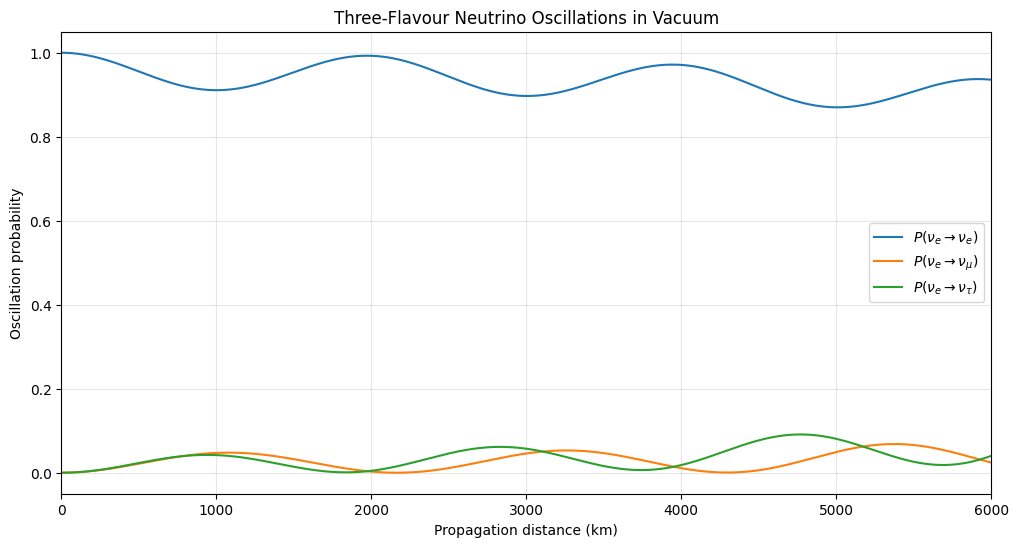

In [19]:
plt.figure(figsize=(12, 6))

plt.plot(L, P_ee, label=r"$P(\nu_e \rightarrow \nu_e)$")
plt.plot(L, P_emu, label=r"$P(\nu_e \rightarrow \nu_\mu)$")
plt.plot(L, P_etau, label=r"$P(\nu_e \rightarrow \nu_\tau)$")

plt.xlabel("Propagation distance (km)")
plt.ylabel("Oscillation probability")
plt.title("Three-Flavour Neutrino Oscillations in Vacuum")

plt.xlim(0, 6000)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

### 9.3 Interpreting the Three-Flavour Results

The three curves describe how the probability of detecting each flavour changes with propagation distance. The electron-neutrino survival probability decreases as probability is transferred to the muon and tau channels, then rises again as the interference between the mass eigenstate contributions changes.

The appearance probabilities need not follow identical patterns. Their detailed behaviour depends on the PMNS matrix elements, the mass-squared differences, and the relative phases accumulated during propagation.

The important point is that the three-flavour model includes two independent mass-squared differences. As a result, the oscillation pattern can contain contributions from more than one characteristic oscillation scale.

Probability conservation provides an additional consistency check. Although the individual probabilities vary with distance, their sum remains equal to unity in the model.


## 10. Comparing the Two-Flavour and Three-Flavour Models

In the previous sections, I implemented both two-flavour and three-flavour models of neutrino oscillations. The two-flavour model provides a relatively simple description using one mixing angle and one mass-squared difference, whereas the three-flavour model includes three mixing angles, two independent mass-squared differences, and a CP-violating phase.

I now want to compare the predictions of these models for the same physical process. Rather than comparing a transition probability in one model with a survival probability in the other, I will examine the appearance probability

$$ P(\nu_\mu \rightarrow \nu_e). $$

For the three-flavour calculation, I will use the PMNS matrix and the parameters defined in the previous sections. For the approximate two-flavour calculation, I will use the leading atmospheric oscillation term:

$$ P(\nu_\mu \rightarrow \nu_e) \approx \sin^2\theta_{23}\sin^2(2\theta_{13}) \sin^2\left(\frac{1.267\,\Delta m_{31}^2L}{E}\right). $$

This approximation retains the dominant atmospheric mass-squared difference while neglecting the solar mass-squared difference and CP-phase-dependent interference terms.

The two calculations therefore describe the same flavour transition but do not include exactly the same physics. I will keep the neutrino energy fixed at $2,\text{GeV}$ and compare the probabilities over the same range of propagation distances. This should help me identify how the simplified approximation differs from the full three-flavour vacuum calculation under the selected conditions.

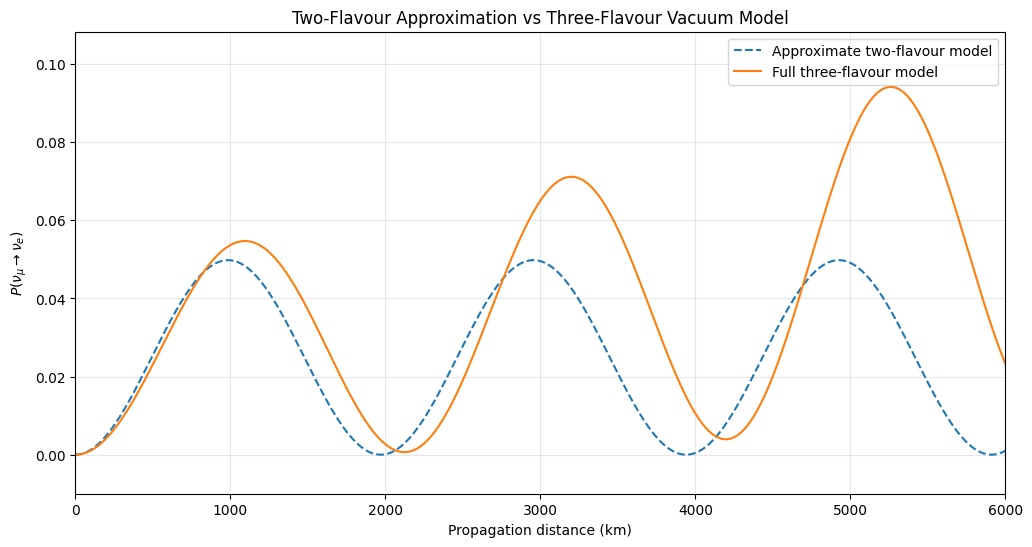

Baseline: 1000 km
Energy: 2.0 GeV
Approximate two-flavour probability: 0.049778
Three-flavour probability:          0.053666
Absolute difference:                0.003888


In [20]:
# Fixed neutrino energy for both calculations
energy_comparison = 2.0  # GeV

# Approximate two-flavour probability for nu_mu -> nu_e
theta23_rad = np.deg2rad(theta23_deg)
theta13_rad = np.deg2rad(theta13_deg)

P_mue_approx = (
    np.sin(theta23_rad)**2
    * np.sin(2 * theta13_rad)**2
    * np.sin(
        1.267 * delta_m31_sq * L / energy_comparison
    )**2
)

# Full three-flavour probability for nu_mu -> nu_e
P_mue_3f = np.array([
    three_flavour_probability(
        alpha=1,
        beta=0,
        distance_km=distance,
        energy_GeV=energy_comparison
    )
    for distance in L
])

# Plot both predictions
plt.figure(figsize=(12, 6))

plt.plot(
    L,
    P_mue_approx,
    linestyle="--",
    label="Approximate two-flavour model"
)

plt.plot(
    L,
    P_mue_3f,
    label="Full three-flavour model"
)

plt.xlabel("Propagation distance (km)")
plt.ylabel(r"$P(\nu_\mu \rightarrow \nu_e)$")
plt.title("Two-Flavour Approximation vs Three-Flavour Vacuum Model")

plt.xlim(0, 6000)
plt.ylim(-0.01, max(P_mue_3f.max(), P_mue_approx.max()) * 1.15)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

# Compare the probabilities at a baseline of 1000 km
comparison_distance = 1000

P_approx_1000 = (
    np.sin(theta23_rad)**2
    * np.sin(2 * theta13_rad)**2
    * np.sin(
        1.267 * delta_m31_sq
        * comparison_distance / energy_comparison
    )**2
)

P_3f_1000 = three_flavour_probability(
    alpha=1,
    beta=0,
    distance_km=comparison_distance,
    energy_GeV=energy_comparison
)

print(f"Baseline: {comparison_distance} km")
print(f"Energy: {energy_comparison} GeV")
print(f"Approximate two-flavour probability: {P_approx_1000:.6f}")
print(f"Three-flavour probability:          {P_3f_1000:.6f}")
print(f"Absolute difference:                {abs(P_3f_1000 - P_approx_1000):.6f}")

### 10.1 Interpreting the Model Comparison
The plot shows how the two-flavour approximation differs from the full three-flavour vacuum model when calculating the appearance probability $P(\nu_\mu \rightarrow \nu_e)$. At a baseline of $1000,\text{km}$ and an energy of $2,\text{GeV}$, the approximate model gives a probability of $0.049778$, while the three-flavour model gives $0.053666$. The absolute difference is approximately $0.003888$.

Although the predictions are relatively close at this baseline, the difference becomes more noticeable at other propagation distances. The approximate model retains the dominant atmospheric oscillation contribution, whereas the three-flavour calculation also includes the solar mass-squared difference and CP-phase-dependent interference. These additional contributions affect the shape and amplitude of the oscillation probability.

This comparison illustrates why the two-flavour approximation is useful for understanding the basic behaviour of neutrino oscillations, but cannot reproduce every feature of the three-flavour model. Both calculations assume vacuum propagation, and the comparison is numerical rather than a validation against experimental measurements.

## 11. Investigating the CP-Violating Phase

The three-flavour framework introduces something that the two-flavour model cannot fully describe: a complex phase in the PMNS mixing matrix, denoted by $\delta_{\mathrm{CP}}$.

This phase is associated with the possibility of charge-parity (CP) violation in neutrino oscillations. In simple terms, CP violation means that the oscillation probability for a neutrino process can differ from that of its corresponding antineutrino process under a CP transformation.

For example, we can compare

$$
P(\nu_\mu \rightarrow \nu_e)
$$

with

$$
P(\bar{\nu}_\mu \rightarrow \bar{\nu}_e).
$$

In vacuum, the neutrino probability is calculated using the PMNS matrix $U$, whereas the antineutrino probability is calculated using its complex conjugate, $U^*$. The mass-squared differences and propagation distance remain unchanged.

If the CP-violating phase is zero or an integer multiple of $\pi$, the standard three-flavour vacuum oscillation model has no intrinsic CP violation. For other phase values, the neutrino and antineutrino probabilities can differ.

In this section, we will vary $\delta_{\mathrm{CP}}$ while keeping the mixing angles, mass-squared differences, energy, and baseline fixed. This will allow us to isolate the effect of the phase on the calculated oscillation probabilities.

The aim is to understand the role of this parameter within the model, rather than to determine its experimentally preferred value.


In [21]:
def build_pmns_matrix(theta12_deg, theta23_deg, theta13_deg, delta_cp_deg):

    # Convert angles to radians
    t12 = np.deg2rad(theta12_deg)
    t23 = np.deg2rad(theta23_deg)
    t13 = np.deg2rad(theta13_deg)
    delta = np.deg2rad(delta_cp_deg)

    # Sines and cosines
    s12, c12 = np.sin(t12), np.cos(t12)
    s23, c23 = np.sin(t23), np.cos(t23)
    s13, c13 = np.sin(t13), np.cos(t13)

    # Complex phase factors
    exp_plus = np.exp(1j * delta)
    exp_minus = np.exp(-1j * delta)

    # PMNS matrix in the standard parameterisation
    U_matrix = np.array([
        [c12*c13, s12*c13, s13*exp_minus],

        [-s12*c23 - c12*s23*s13*exp_plus,
         c12*c23 - s12*s23*s13*exp_plus,
         s23*c13],

        [s12*s23 - c12*c23*s13*exp_plus,
         -c12*s23 - s12*c23*s13*exp_plus,
         c23*c13]
    ], dtype=complex)

    return U_matrix

I have written the PMNS matrix as a function so that I can change the CP phase without having to rewrite the entire matrix every time. The three mixing angles are converted from degrees to radians before calculating the matrix elements.

The complex exponential terms are where the CP phase enters the matrix. Since neutrino oscillations depend on the interference between different mass eigenstates, changing these phases can change the resulting transition probabilities.

I'll use this function to construct several matrices with different values of $\delta_{\mathrm{CP}}$, while keeping the mixing angles at the same representative values used in the previous section.

In [22]:
theta12_deg = 33.4
theta23_deg = 49.0
theta13_deg = 8.6

delta_values = [0, 90, 180, 270, 195]

pmns_matrices = {
    delta: build_pmns_matrix(
        theta12_deg,
        theta23_deg,
        theta13_deg,
        delta
    )
    for delta in delta_values
}

# Check unitarity for every matrix
for delta, U_test in pmns_matrices.items():
    identity_check = U_test.conj().T @ U_test

    print(
        f"δ_CP = {delta:3d}° | "
        f"Maximum unitarity deviation: "
        f"{np.max(np.abs(identity_check - np.eye(3))):.2e}"
    )

δ_CP =   0° | Maximum unitarity deviation: 6.27e-17
δ_CP =  90° | Maximum unitarity deviation: 2.95e-17
δ_CP = 180° | Maximum unitarity deviation: 5.65e-17
δ_CP = 270° | Maximum unitarity deviation: 4.44e-17
δ_CP = 195° | Maximum unitarity deviation: 2.22e-16


Before using these matrices to calculate oscillation probabilities, I want to check that they satisfy the unitarity condition,

$$ U^\dagger U=I. $$

This is an important consistency check because the PMNS matrix must be unitary in the standard three-flavour framework used here.

The code calculates the conjugate transpose of each matrix, multiplies it by the original matrix, and compares the result with the identity matrix. The printed deviation gives me a numerical measure of how closely the condition is satisfied.

I expect the deviations to be extremely small, arising from floating-point precision rather than a physical discrepancy. Passing this check does not validate the entire oscillation model, but it confirms that the matrices have been constructed consistently before I use them in the subsequent calculations.

### 11.1 Calculating the transition probability
The next step is to calculate the probability of a muon neutrino being detected as an electron neutrino. In the three-flavour model, the probability depends on the contributions from all three mass eigenstates, including the relative phases accumulated during propagation.

I'll reuse the probability calculation developed in the previous section. The only addition is that the function will accept a PMNS matrix as an argument, allowing me to calculate probabilities for different CP phases using the same implementation.

In [23]:
def oscillation_probability(
    alpha,
    beta,
    distance_km,
    energy_GeV,
    U_matrix
):
    phase = 2 * 1.267 * mass_sq * distance_km / energy_GeV

    amplitude = np.sum(
        U_matrix[beta, :]
        * np.conj(U_matrix[alpha, :])
        * np.exp(-1j * phase)
    )

    return np.abs(amplitude)**2

The function calculates the propagation phase for each mass eigenstate and combines their contributions into a single complex amplitude. Taking the squared magnitude of this amplitude gives the transition probability.

I've retained the same units and mass-squared array used in the earlier three-flavour calculation, so the model remains consistent with the previous sections. The flavour indices are also unchanged: 0 represents electron neutrinos, 1 represents muon neutrinos, and 2 represents tau neutrinos.

For the present investigation, I'll use indices 1 and 0 to calculate $P(\nu_\mu\rightarrow\nu_e)$. For antineutrinos, I'll supply the complex conjugate of the PMNS matrix, as required by the vacuum oscillation formalism.

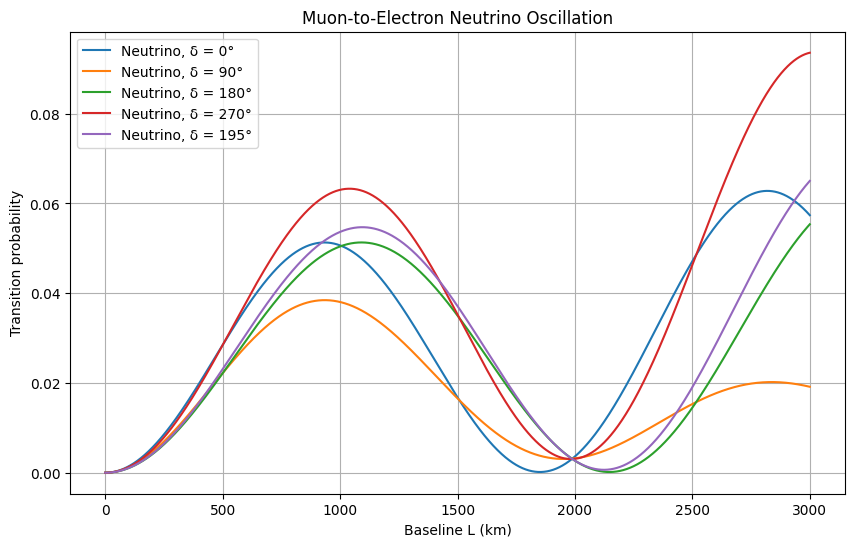

In [24]:
energy_cp = 2.0
L_cp = np.linspace(0, 3000, 3000)

delta_to_plot = [0, 90, 180, 270, 195]

plt.figure(figsize=(10, 6))

for delta in delta_to_plot:

    U_test = pmns_matrices[delta]

    # Neutrino: use U
    P_nu = np.array([
        oscillation_probability(1, 0, distance, energy_cp, U_test)
        for distance in L_cp
    ])

    # Antineutrino: use the complex conjugate of U
    P_anti = np.array([
        oscillation_probability(1, 0, distance, energy_cp, np.conj(U_test))
        for distance in L_cp
    ])

    plt.plot(
        L_cp,
        P_nu,
        label=f"Neutrino, δ = {delta}°"
    )

plt.xlabel("Baseline L (km)")
plt.ylabel("Transition probability")
plt.title("Muon-to-Electron Neutrino Oscillation")
plt.legend()
plt.grid(True)
plt.show()

I have fixed the neutrino energy at 2 GeV and varied the baseline from zero to 3000 km. For each selected value of $\delta_{\mathrm{CP}}$, the code calculates the transition probability across the entire baseline range.

I mainly want this plot to show whether changing the CP phase alters the oscillation pattern. Since the other parameters remain fixed, differences between the curves can be attributed to the phase within this model.

At zero baseline, the transition probability should be zero because the initial muon neutrino has not propagated far enough to develop a transition probability. As the baseline increases, the contributions from the mass eigenstates acquire different phases, producing the oscillatory behaviour.

The extent to which the curves differ is something I'll examine from the actual plot rather than assume in advance. Next, I'll repeat the calculation for antineutrinos so that the two processes can be compared under identical propagation conditions.

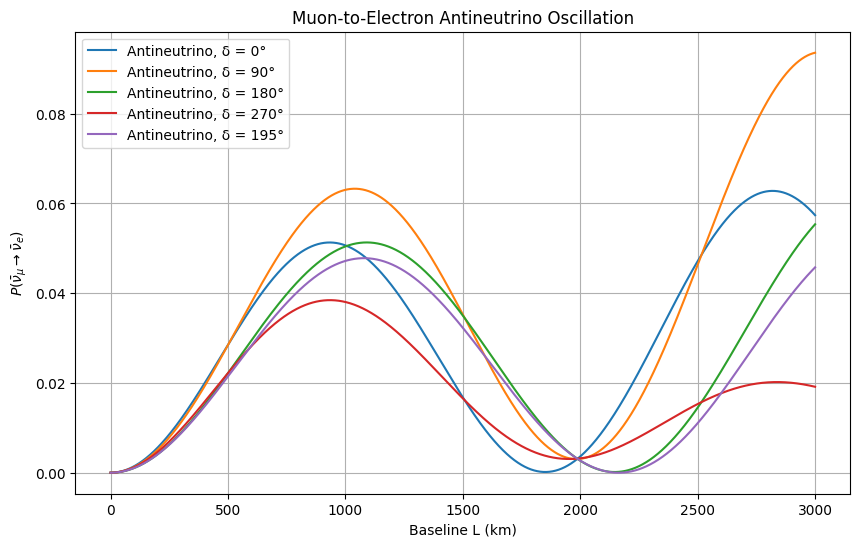

In [28]:
plt.figure(figsize=(10, 6))

for delta in delta_to_plot:

    U_test = pmns_matrices[delta]

    P_anti = np.array([
        oscillation_probability(
            1, 0, distance, energy_cp, np.conj(U_test)
        )
        for distance in L_cp
    ])

    plt.plot(
        L_cp,
        P_anti,
        label=f"Antineutrino, δ = {delta}°"
    )

plt.xlabel("Baseline L (km)")
plt.ylabel(r"$P(\bar{\nu}_\mu \rightarrow \bar{\nu}_e)$")
plt.title("Muon-to-Electron Antineutrino Oscillation")
plt.legend()
plt.grid(True)
plt.show()

This plot follows the same procedure as the previous one, but uses the complex-conjugated PMNS matrix to calculate the antineutrino probabilities.

Keeping the energy, baseline range, and mixing angles unchanged makes the comparison more meaningful. Any difference between the corresponding neutrino and antineutrino probabilities comes from the different phase structure in their amplitudes, given our vacuum assumptions.

The two plots provide a useful visual comparison, but they are not the easiest way to quantify small differences. To make the investigation more direct, I'll calculate the difference between the probabilities and examine how it varies with baseline.

### 11.2 Quantifying the CP asymmetry
I'll define the CP asymmetry for this investigation as the difference between the neutrino and antineutrino transition probabilities:

$$ A_{\mathrm{CP}} = P(\nu_\mu\rightarrow\nu_e) - P(\bar{\nu}_\mu\rightarrow\bar{\nu}_e). $$

This definition is convenient because it directly measures the difference between the two probabilities. A positive value means the neutrino transition probability is larger, while a negative value means the antineutrino transition probability is larger.

I'll calculate this quantity for the same CP phases and baseline range used above. This should make it easier to identify where the two probabilities differ and whether the difference changes as the neutrinos propagate.

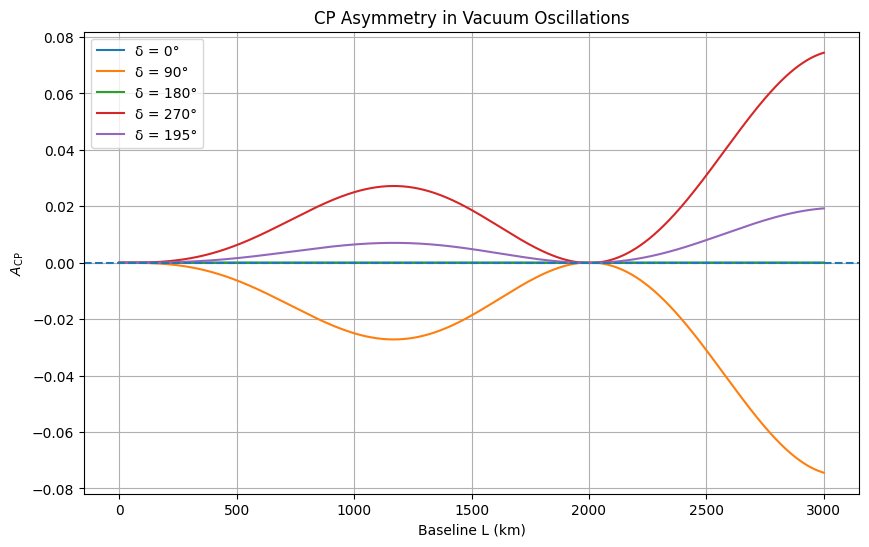

In [26]:
plt.figure(figsize=(10, 6))

for delta in delta_to_plot:

    U_test = pmns_matrices[delta]

    P_nu = np.array([
        oscillation_probability(
            1, 0, distance, energy_cp, U_test
        )
        for distance in L_cp
    ])

    P_anti = np.array([
        oscillation_probability(
            1, 0, distance, energy_cp, np.conj(U_test)
        )
        for distance in L_cp
    ])

    A_CP = P_nu - P_anti

    plt.plot(
        L_cp,
        A_CP,
        label=f"δ = {delta}°"
    )

plt.axhline(0, linestyle="--")
plt.xlabel("Baseline L (km)")
plt.ylabel(r"$A_{\mathrm{CP}}$")
plt.title("CP Asymmetry in Vacuum Oscillations")
plt.legend()
plt.grid(True)
plt.show()

I have subtracted the antineutrino probability from the neutrino probability at every baseline. The horizontal line at zero represents the case in which the two probabilities are equal.

I want to examine both the magnitude and the sign of the asymmetry. If a curve crosses zero, it means that the ordering of the two probabilities reverses at that baseline. This does not mean that the CP phase itself has changed; the phase is fixed for each curve, while the relative propagation phases of the mass eigenstates continue to evolve.

For $\delta_{\mathrm{CP}}=0^\circ$ and $180^\circ$, the intrinsic CP asymmetry should vanish in this vacuum model, apart from numerical precision. For other values, a nonzero asymmetry can arise.

The plot therefore provides a more direct way to investigate the role of the CP phase than looking at the individual probability curves alone. I'll also inspect the numerical values at a single baseline to make the comparison easier to quantify.

In [27]:
baseline_test = 1000  # km

print(f"Energy: {energy_cp} GeV")
print(f"Baseline: {baseline_test} km\n")

for delta in delta_to_plot:

    U_test = pmns_matrices[delta]

    P_nu = oscillation_probability(
        1, 0, baseline_test, energy_cp, U_test
    )

    P_anti = oscillation_probability(
        1, 0, baseline_test, energy_cp, np.conj(U_test)
    )

    A_CP = P_nu - P_anti

    print(
        f"δ = {delta:3d}° | "
        f"P(νμ → νe) = {P_nu:.5f} | "
        f"P(ν̄μ → ν̄e) = {P_anti:.5f} | "
        f"A_CP = {A_CP:+.5f}"
    )

Energy: 2.0 GeV
Baseline: 1000 km

δ =   0° | P(νμ → νe) = 0.05065 | P(ν̄μ → ν̄e) = 0.05065 | A_CP = +0.00000
δ =  90° | P(νμ → νe) = 0.03804 | P(ν̄μ → ν̄e) = 0.06304 | A_CP = -0.02500
δ = 180° | P(νμ → νe) = 0.05043 | P(ν̄μ → ν̄e) = 0.05043 | A_CP = +0.00000
δ = 270° | P(νμ → νe) = 0.06304 | P(ν̄μ → ν̄e) = 0.03804 | A_CP = +0.02500
δ = 195° | P(νμ → νe) = 0.05367 | P(ν̄μ → ν̄e) = 0.04720 | A_CP = +0.00647


The final calculation evaluates both probabilities at a baseline of 1000 km and an energy of 2 GeV. This gives me a numerical comparison for each CP phase without having to estimate values from the plots.

The most useful comparison is between the cases where the CP phase is zero or $180^\circ$ and those where it takes other values. The first two should produce equal neutrino and antineutrino probabilities in vacuum, whereas the other cases can produce a difference.

I'll use these values alongside the asymmetry plot to discuss how strongly the CP phase influences the transition probability under the selected conditions. The results will describe the behaviour of the model at this energy and baseline, rather than establish a universal value for the asymmetry.

### 11.3 Interpretation of Results
The calculations allow me to investigate how the CP-violating phase affects the transition probabilities in the three-flavour vacuum model. The unitarity checks confirm that the PMNS matrices satisfy the expected mathematical condition to numerical precision, while the probability plots show how the predicted oscillation pattern changes as the phase is varied.

The comparison between neutrinos and antineutrinos is particularly useful because it isolates a feature that cannot be fully described by the standard two-flavour vacuum approximation. A nonzero difference between their transition probabilities demonstrates the role of the complex phase in the interference between the mass eigenstates.

However, these results need to be interpreted within the limitations of the model. The calculations use representative mixing parameters and assume vacuum propagation. In an actual experiment, matter effects can also produce differences between neutrino and antineutrino probabilities, so an observed asymmetry would not automatically establish intrinsic CP violation.

This section therefore extends the earlier numerical investigation by showing how the CP phase enters the three-flavour framework. It does not determine the experimentally preferred value of the phase or establish agreement with experimental measurements.

### 12. Conclusion and Limitations
In this project, I investigated neutrino oscillations through numerical simulation, beginning with the two-flavour approximation and gradually moving towards a more complete three-flavour description. My main objective was to understand how the theoretical framework translates into numerical predictions and how those predictions change when different physical parameters are varied.

The two-flavour model provided a starting point for studying the dependence of oscillation probability on propagation distance, neutrino energy, mixing angle, and mass-squared difference. I also compared the numerically calculated oscillation maximum with its analytical prediction. The close agreement between these results gave me confidence that the implementation was consistent with the underlying mathematical expression.

I then extended the investigation to three-flavour oscillations using the PMNS matrix. Checking its unitarity and verifying that the flavour-transition probabilities sum to unity provided important consistency checks for the numerical model. Comparing the two-flavour approximation with the three-flavour calculation also demonstrated how including additional mass-squared differences and interference effects changes the predicted oscillation probability.

Finally, I investigated the role of the CP-violating phase by calculating neutrino and antineutrino appearance probabilities. The resulting asymmetry varied with the selected phase, illustrating how the three-flavour framework can produce different oscillation probabilities for neutrinos and antineutrinos even in vacuum.

There are, however, important limitations to this investigation. The calculations assume vacuum propagation and coherent oscillations, and the initial model uses a two-flavour approximation. Although the three-flavour model incorporates a more complete description of vacuum oscillations, the project does not include matter effects, which can influence neutrino propagation through the Earth. Furthermore, the numerical results are theoretical predictions based on selected oscillation parameters; they have not been fitted to experimental data or used to establish new constraints on neutrino properties.

For me, the most useful outcome of this project was connecting the mathematical description of neutrino oscillations with a working computational model. It also highlighted the limitations of simplifying a physical system and the importance of checking numerical results against theoretical expectations. This provides a foundation for a future investigation involving matter effects, experimental neutrino data, or a more detailed study of CP violation.